## Group 2
#### Elias Bergset, Ludvik Høibjerg-Aslaksen, Viktor Mattias Larøi Hedman

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# Imports 
telecom_df = pd.read_csv(r"trainCA4DAT200.csv")

telecom_df = telecom_df.drop(columns="CustomerId")

### EDA

In [14]:
telecom_df.describe()

,AccountLength,AreaCode,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
count,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000
mean,99.996571,436.915429,8.112000,180.292429,100.016286,30.650306,200.763000,100.178000,17.065066,199.984857,99.669714,8.999397,10.297714,4.417143,2.780829,1.567714,0.141429
std,39.471509,42.169180,13.728371,53.764503,19.852587,9.139923,50.561814,19.800506,4.297740,50.132089,20.064302,2.256017,2.719716,2.456653,0.734263,1.298641,0.348513
min,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,73.000000,415.000000,0.000000,143.700000,87.000000,24.430000,165.900000,87.000000,14.100000,166.700000,86.000000,7.500000,8.600000,3.000000,2.320000,1.000000,0.000000
50%,100.000000,415.000000,0.000000,179.700000,100.000000,30.550000,201.050000,100.000000,17.090000,199.700000,100.000000,8.990000,10.400000,4.000000,2.810000,1.000000,0.000000
75%,126.000000,415.000000,19.000000,216.525000,113.000000,36.812500,235.225000,113.000000,19.992500,233.625000,113.000000,10.512500,12.000000,6.000000,3.240000,2.000000,0.000000
max,243.000000,510.000000,52.000000,351.500000,163.000000,59.760000,361.800000,170.000000,30.750000,395.000000,175.000000,17.770000,20.000000,19.000000,5.400000,9.000000,1.000000


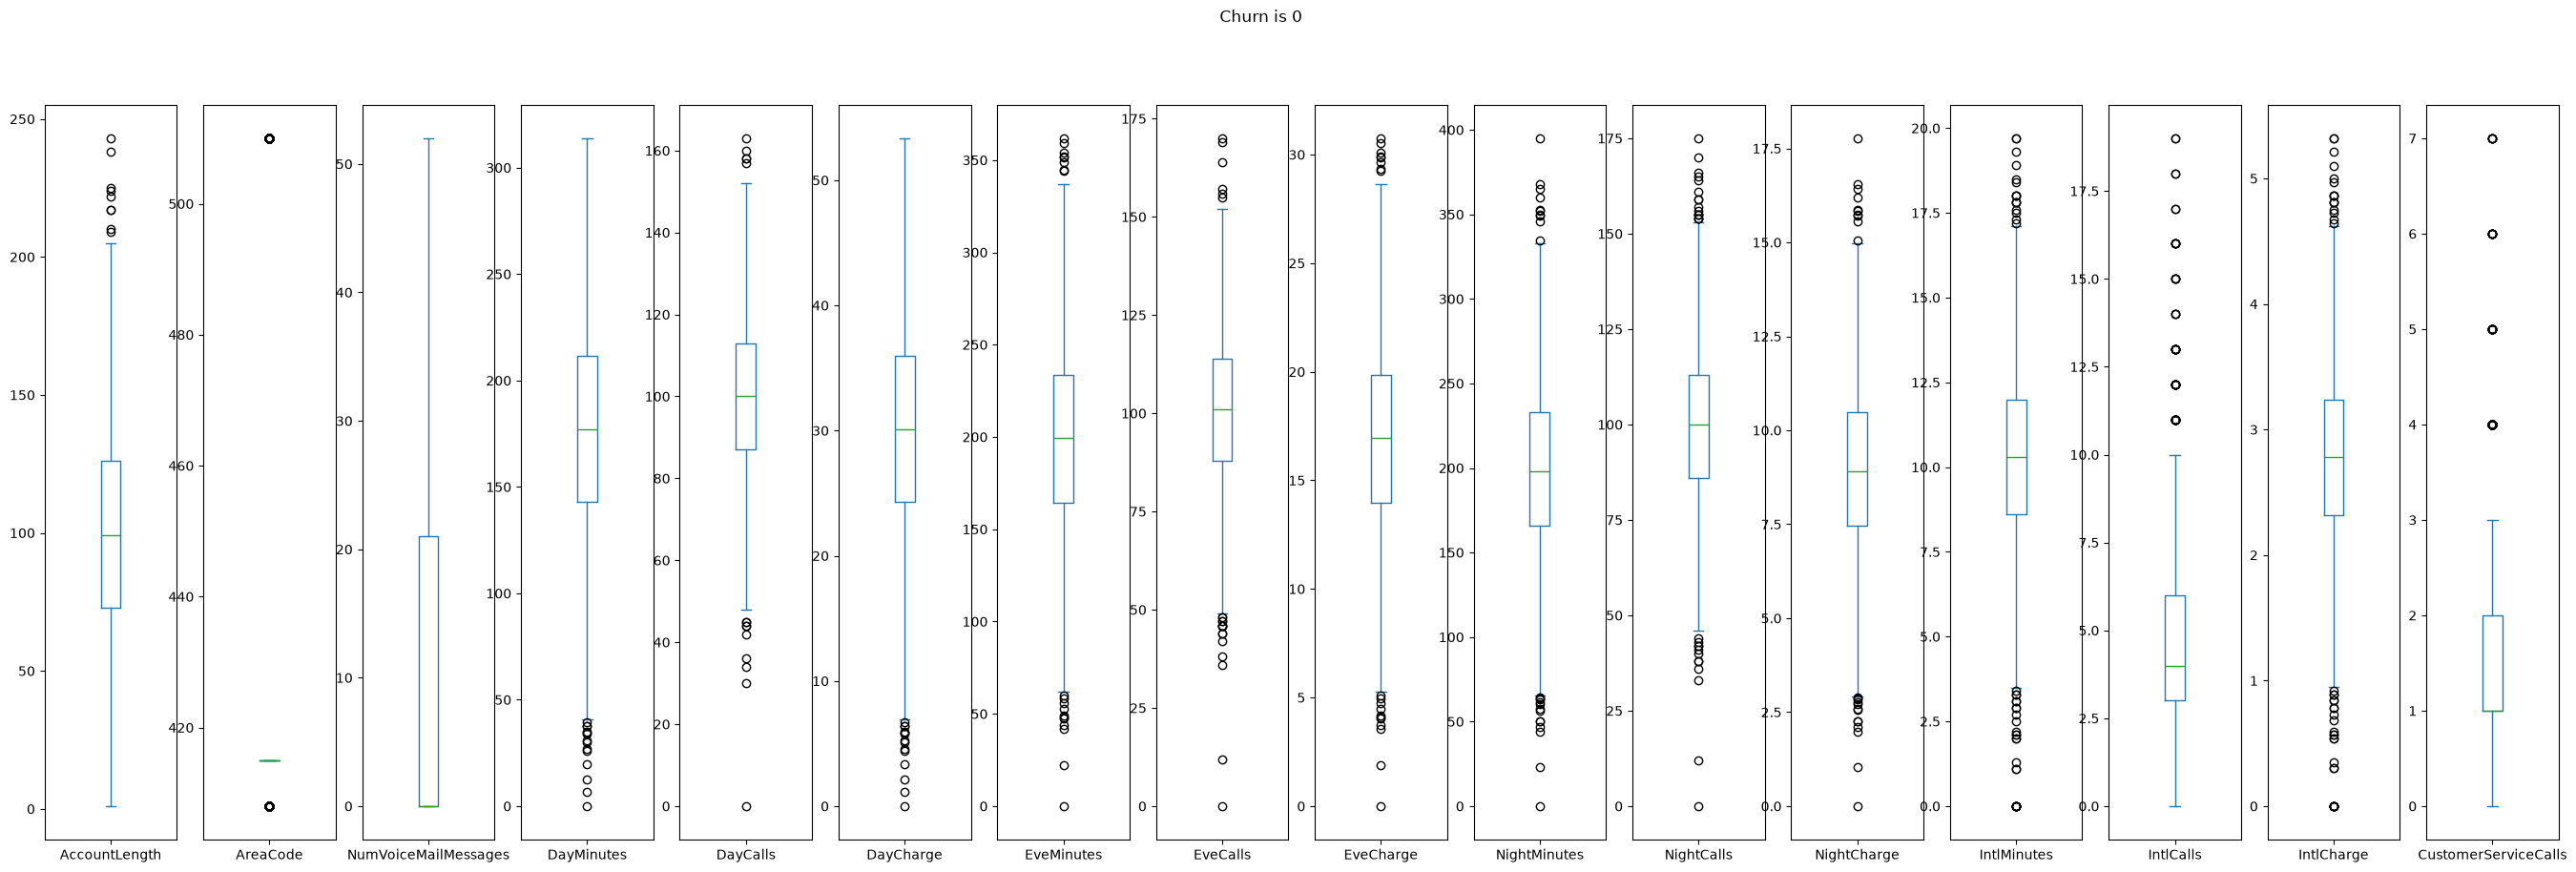

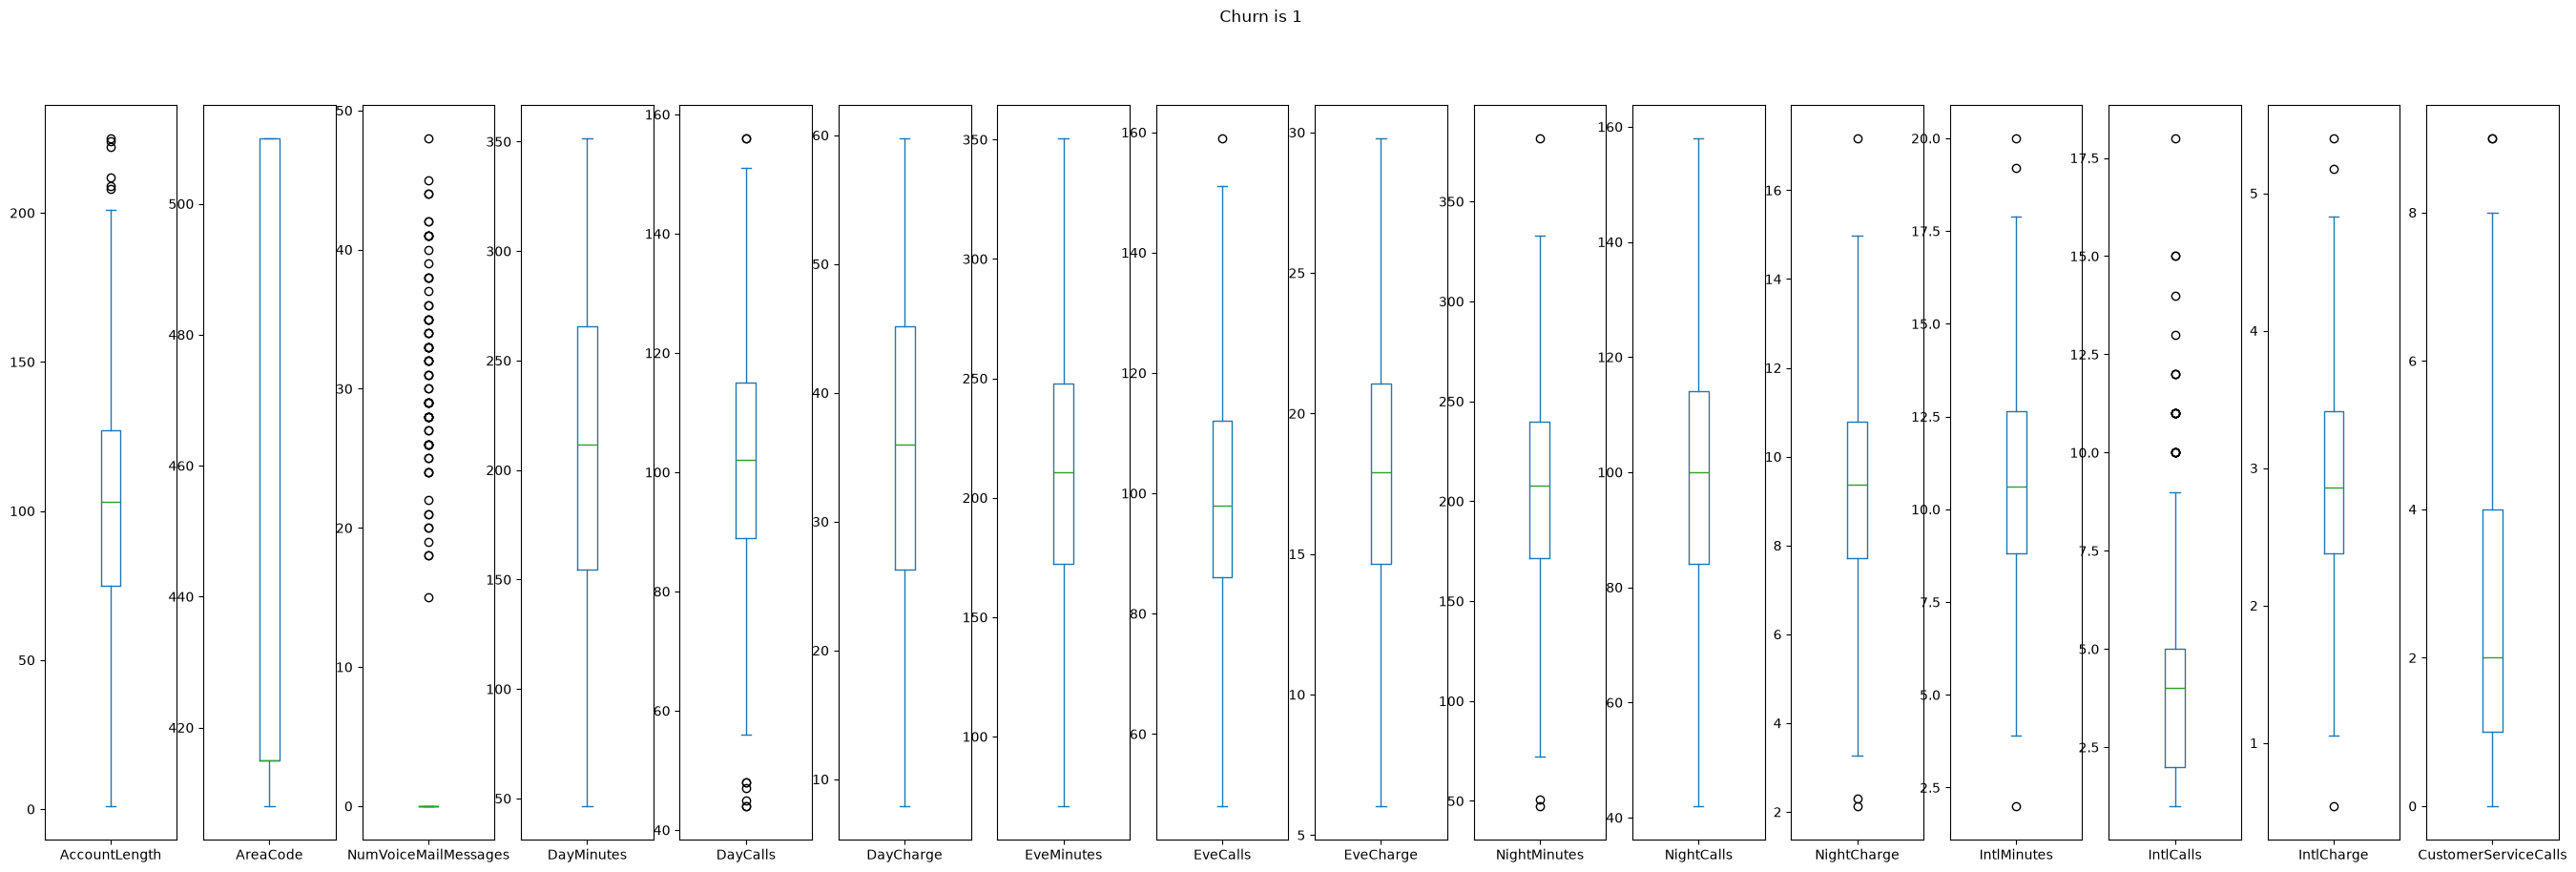

In [15]:
no_churn_df = telecom_df.loc[telecom_df["Churn"]==0].drop(columns="Churn")
yes_churn_df = telecom_df.loc[telecom_df["Churn"]==1].drop(columns="Churn")

no_churn_df.plot.box(subplots=True, figsize=(34, 10), title="Churn is 0")
yes_churn_df.plot.box(subplots=True, figsize=(34, 10), title="Churn is 1")
plt.show()

AccountLength: Too little difference

AreaCode: Irrelevant comparison

NumVoiceMailMessages: Customers that stayed tended to have a more even spread while leavers had many outliers and a small spread

DayMinutes: Too little difference 

DayCalls: Too little difference

DayCharge: Higher spread in Churn is 1

EveMinutes: Similar spread, but more outliers in churn is 0

EveCalls: Tighter spread and more outliers on churn is 0

EveCharge: Same as EveCalls

NightMinutes, NightCalls, NightCharge: Same pattern as EveCalls

IntlMinutes, IntlCalls, IntlCharge: Also follows the same pattern as EveCalls

CustomerServiceCalls: churn is 1 shows that people that left tended a to have more customer service calls

Most features show very similar plots minor differences except CustomerServiceCalls which show a that more service calls tend make people leave

In [16]:
no_bar_churn_df = telecom_df.loc[telecom_df["Churn"]==0].drop(columns="Churn")
yes_bar_churn_df = telecom_df.loc[telecom_df["Churn"]==1].drop(columns="Churn")

no_bar_churn_df = no_bar_churn_df.select_dtypes(include="string").drop(columns="State")
yes_bar_churn_df = yes_bar_churn_df.select_dtypes(include="string").drop(columns="State")

amount_yes_no_churn = no_bar_churn_df.replace(to_replace=["yes", "no"], value=[1, 0]).sum()
entries_no_churn = len(no_bar_churn_df)

amount_yes_yes_churn = yes_bar_churn_df.replace(to_replace=["yes", "no"], value=[1, 0]).sum()
entries_yes_churn = len(yes_bar_churn_df)

print(f"Percentage of users who stayed that had an international plan: {(amount_yes_no_churn["InternationalPlan"]/entries_no_churn)*100:.2f}%")
print(f"Percentage of users who stayed that had a voice mail plan: {(amount_yes_no_churn["VoiceMailPlan"]/entries_no_churn)*100:.2f}%\n")

print(f"Percentage of users who left that had an international plan: {(amount_yes_yes_churn["InternationalPlan"]/entries_yes_churn)*100:.2f}%")
print(f"Percentage of users who left that had a voice mail plan: {(amount_yes_yes_churn["VoiceMailPlan"]/entries_yes_churn)*100:.2f}%")

Percentage of users who stayed that had an international plan: 6.39%
Percentage of users who stayed that had a voice mail plan: 29.85%

Percentage of users who left that had an international plan: 28.28%
Percentage of users who left that had a voice mail plan: 14.75%


This data shows that people with an international plan are more likely to change provider while people that a voice mail plan are more likely to stay

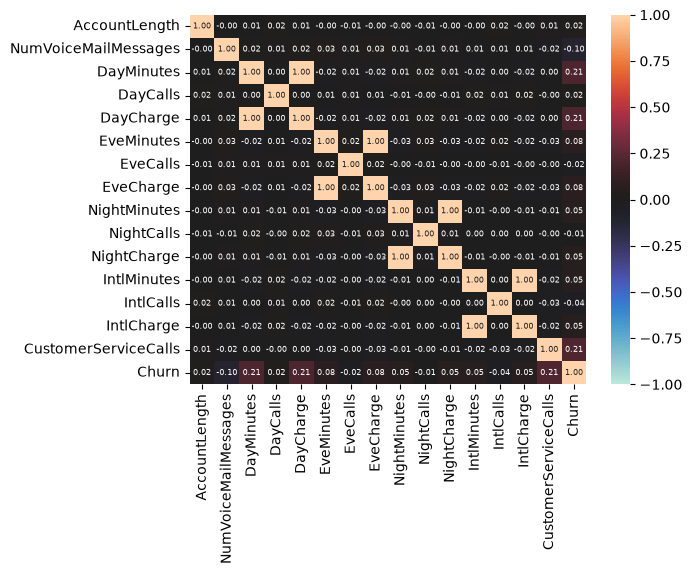

In [17]:
telecom_df_corr = telecom_df.select_dtypes(include="number").drop(columns=["AreaCode"]).corr()
sns.heatmap(telecom_df_corr, annot=True, vmin=-1, vmax=1, center=0, fmt=".2f", annot_kws={"size": 6})
plt.show()

The heatmap clearly shows that charge and minutes are completely dependent that's because charge is calculated from minutes. Charge can safely be ignored without losing any information.

### Data Cleaning

In [18]:
telecom_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   State                 3500 non-null   str    
 1   AccountLength         3500 non-null   int64  
 2   AreaCode              3500 non-null   int64  
 3   InternationalPlan     3500 non-null   str    
 4   VoiceMailPlan         3500 non-null   str    
 5   NumVoiceMailMessages  3500 non-null   int64  
 6   DayMinutes            3500 non-null   float64
 7   DayCalls              3500 non-null   int64  
 8   DayCharge             3500 non-null   float64
 9   EveMinutes            3500 non-null   float64
 10  EveCalls              3500 non-null   int64  
 11  EveCharge             3500 non-null   float64
 12  NightMinutes          3500 non-null   float64
 13  NightCalls            3500 non-null   int64  
 14  NightCharge           3500 non-null   float64
 15  IntlMinutes           3500 non-n

In [19]:
(telecom_df.select_dtypes(include="number") < 0).any()

AccountLength           False
AreaCode                False
NumVoiceMailMessages    False
DayMinutes              False
DayCalls                False
DayCharge               False
EveMinutes              False
EveCalls                False
EveCharge               False
NightMinutes            False
NightCalls              False
NightCharge             False
IntlMinutes             False
IntlCalls               False
IntlCharge              False
CustomerServiceCalls    False
Churn                   False
dtype: bool

In [20]:
telecom_df = telecom_df.drop(columns=["State", "AreaCode", "DayCharge", "EveCharge", "NightCharge", "IntlCharge"])
telecom_df = telecom_df.replace(to_replace=["yes", "no"], value=[1, 0])

State and AreaCode don't provide useful information without many more datapoints therefore they are removed. Change yes to ones and no to 0 zeros such scaling works

### EDA after cleaning

After cleaing all features are numeric and irrelevant columns have been removed.

### Pipelines

In [21]:
# Pipeline imports
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import TunedThresholdClassifierCV, train_test_split
from sklearn.base import clone


In [22]:
# Separate into X and y
telecom_df_y = telecom_df["Churn"]
telecom_df_X = telecom_df.drop(columns="Churn")

In [23]:
# Svc pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('svc', SVC()),])

params = {
    'pca__n_components': [0.80, 0.85, 0.90, 0.95, 0.99, None],   
    'svc__C': np.logspace(-2, 3, 10),
    'svc__gamma': np.logspace(-4, 1, 10),
    'svc__class_weight': ['balanced'],
}

cv = StratifiedKFold(n_splits=10)

gs = GridSearchCV(pipe, params, cv=cv, scoring='f1_macro', n_jobs=-1)

gs.fit(telecom_df_X, telecom_df_y)

best_params = gs.best_params_
for bp in best_params:
    print(f"{bp}: {best_params[bp]}")

print(f"The f1 macro score of the current classifier is: {gs.best_score_:.4f}")

pca__n_components: 0.95
svc__C: 5.994842503189409
svc__class_weight: balanced
svc__gamma: 0.05994842503189409
The f1 macro score of the current classifier is: 0.8148


In [24]:
# ExtraTress Pipeline
pipe_ET = Pipeline([
    ('extratrees', ExtraTreesClassifier()),])

params_ET = {
    "extratrees__n_estimators": [200],
    "extratrees__max_depth": [5, 10, 15, None],
    "extratrees__min_samples_split": [2, 8, 12],
    "extratrees__max_features": ["sqrt", "log2", None],
    "extratrees__max_leaf_nodes": [2, 10, None],
}

cv_ET = StratifiedKFold(n_splits=10)

gs_ET = GridSearchCV(pipe_ET, params_ET, cv=cv_ET, scoring='f1_macro', n_jobs=-1)
gs_ET.fit(telecom_df_X, telecom_df_y)

best_params = gs_ET.best_params_
for bp in best_params:
    print(f"{bp}: {best_params[bp]}")

gs_ET_tuned = TunedThresholdClassifierCV(gs_ET.best_estimator_, scoring='f1_macro').fit(telecom_df_X, telecom_df_y)

print(f"The f1 macro score of the current classifier with default threshold is:: {gs_ET.best_score_:.4f}")
print(f"Best threshold: {gs_ET_tuned.best_threshold_:.4f}")
print(f"The f1 macro score of the current classifier with tuned threshold is: {gs_ET_tuned.best_score_:.4f}")

extratrees__max_depth: None
extratrees__max_features: None
extratrees__max_leaf_nodes: None
extratrees__min_samples_split: 8
extratrees__n_estimators: 200
The f1 macro score of the current classifier with default threshold is:: 0.9069
Best threshold: 0.4132
The f1 macro score of the current classifier with tuned threshold is: 0.9095


In [25]:
# Gradient boosting Pipeline
pipe_GB = Pipeline([
    ('gb', GradientBoostingClassifier()),])

params_GB = {
    "gb__n_estimators": [200],
    "gb__learning_rate": [0.1, 0.4, 0.7, 1],
    "gb__max_depth": [2, 4, 6, None],
    "gb__subsample": [0.6, 0.8, 1.0]
}

cv_GB = StratifiedKFold(n_splits=10)

gs_GB = GridSearchCV(pipe_GB, params_GB, cv=cv_GB, scoring='f1_macro', n_jobs=-1)
gs_GB.fit(telecom_df_X, telecom_df_y)

gs_GB_tuned = TunedThresholdClassifierCV(gs_GB.best_estimator_, scoring='f1_macro').fit(telecom_df_X, telecom_df_y)

best_params = gs_GB.best_params_
for bp in best_params:
    print(f"{bp}: {best_params[bp]}")

print(f"The f1 macro score of the current classifier with default threshold is:: {gs_GB.best_score_:.4f}")
print(f"Best threshold: {gs_GB_tuned.best_threshold_:.4f}")
print(f"The f1 macro score of the current classifier is: {gs_GB_tuned.best_score_:.4f}")

gb__learning_rate: 0.1
gb__max_depth: 6
gb__n_estimators: 200
gb__subsample: 0.6
The f1 macro score of the current classifier with default threshold is:: 0.9045
Best threshold: 0.2829
The f1 macro score of the current classifier is: 0.9093


In [26]:
# LogReg Pipeline
pipe_LR = Pipeline([
    ('scaler', StandardScaler()),
    # ('pca', PCA()),
    ('lr', LogisticRegression()),])

params_LR = [
    { 
        'lr__solver': ['lbfgs'],
        'lr__l1_ratio': [0],
        'lr__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'lr__class_weight': ['balanced'],
    },
    { 
        'lr__solver': ['liblinear'],
        'lr__l1_ratio': [0, 1],
        'lr__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'lr__class_weight': ['balanced'],
    },
    { 
        'lr__solver': ['saga'],
        'lr__l1_ratio': [0, 0.2, 0.5, 0.6, 0.8, 0.9, 1],
        'lr__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'lr__class_weight': ['balanced'],
    },
]

cv_LR = StratifiedKFold(n_splits=10)

gs_LR = GridSearchCV(pipe_LR, params_LR, cv=cv_LR, scoring='f1_macro', n_jobs=-1)

gs_LR.fit(telecom_df_X, telecom_df_y)

best_params = gs_LR.best_params_
for bp in best_params:
    print(f"{bp}: {best_params[bp]}")

print(f"The f1 macro score of the current classifier is: {gs_LR.best_score_:.4f}")

lr__C: 0.001
lr__class_weight: balanced
lr__l1_ratio: 0
lr__solver: lbfgs
The f1 macro score of the current classifier is: 0.6750


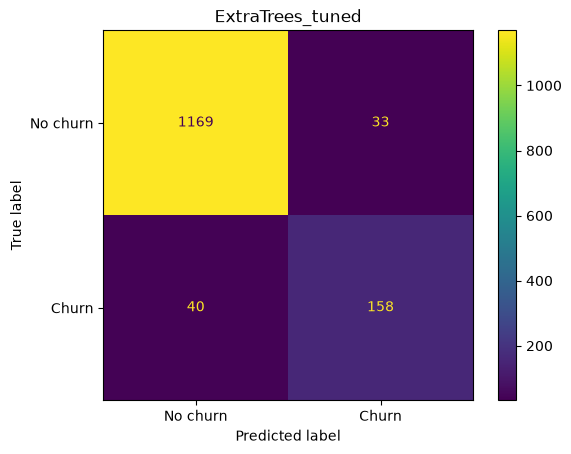

In [27]:
# Confusion Matrix for best model with a 60/40 split
models = {
    "svc" : gs,
    "ExtraTrees": gs_ET,
    "ExtraTrees_tuned" : gs_ET_tuned,
    "GradientBoosting" : gs_GB,
    "GradientBoosting_tuned" : gs_GB_tuned,
    "LogReg" : gs_LR}

X_train, X_test, y_train, y_test = train_test_split(telecom_df_X, telecom_df_y, test_size=0.4, stratify=telecom_df_y)

best_model = "svc"
for model_name in models:
    if models[best_model].best_score_ < models[model_name].best_score_:
        best_model = model_name

if "tuned" not in best_model: 
    final_model = clone(models[best_model].best_estimator_)
else:
    final_model = clone(models[best_model])

final_model.fit(X_train, y_train)

cm = confusion_matrix(y_test, final_model.predict(X_test))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No churn", "Churn"])
disp.plot()
disp.ax_.set_title(best_model)
plt.show()

The best model shows a high accuracy with very few false positives and false negatives

In [28]:
# Import test set
telecom_df_test = pd.read_csv(r"testCA4DAT200.csv")
telecom_df_test = telecom_df_test.drop(columns=["State", "AreaCode", "DayCharge", "EveCharge", "NightCharge", "IntlCharge"])
telecom_df_test = telecom_df_test.replace(to_replace=["yes", "no"], value=[1, 0])

customerId_df = telecom_df_test["CustomerId"]
telecom_df_test = telecom_df_test.drop(columns="CustomerId")

In [29]:
# Export results of all models
from pathlib import Path

Path("results").mkdir(exist_ok=True)

for model in models:
    submission = pd.DataFrame(models[model].predict(telecom_df_test), columns=["Churn"])

    submission["CustomerId"] = customerId_df
    submission = submission.set_index("CustomerId")

    submission.to_csv(f"results/Kaggle_{model}_pipeline_result.csv")